In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Saving placement_predict_50k Dataset.csv to placement_predict_50k Dataset.csv
Dataset loaded successfully!
Shape: (50000, 32)
Columns: ['StudentID', 'Gender', 'City', 'CollegeTier', 'Stream', 'Specialisation', 'Hostel', 'HistoryOfBacklogs', 'SGPA_Sem1', 'SGPA_Sem2', 'SGPA_Sem3', 'SGPA_Sem4', 'SGPA_Sem5', 'SGPA_Sem6', 'SGPA_Sem7', 'SGPA_Sem8', 'CGPA', 'AttendancePercent', 'Internships', 'Projects', 'Workshops', 'Certifications', 'Publications', 'AptitudeTestScore', 'SoftSkillsRating', 'CodingTestScore', 'MockInterviewScore', 'ExtraCurricular', 'CGPA_Tier', 'PlacementStatus', 'IsAnomaly', 'Salary Package']


,StudentID,Gender,City,CollegeTier,Stream,Specialisation,Hostel,HistoryOfBacklogs,SGPA_Sem1,SGPA_Sem2,...,Publications,AptitudeTestScore,SoftSkillsRating,CodingTestScore,MockInterviewScore,ExtraCurricular,CGPA_Tier,PlacementStatus,IsAnomaly,Salary Package
0,1,Male,Ahmedabad,Tier2,ECE,Networking,No,No,6.02,6.54,...,0,66.7,2.2,49.4,47.8,0,Low,0,0,0.00
1,2,Female,Mumbai,Tier2,ECE,DataScience,Yes,Yes,5.84,5.12,...,0,48.2,2.4,26.7,25.8,0,Low,0,0,0.00
2,3,Male,Kolkata,Tier2,IT,DataScience,Yes,No,4.91,5.29,...,0,73.8,2.8,67.7,41.5,0,Low,1,0,3.89
3,4,Male,Jaipur,Tier1,CS,AI,No,No,7.67,8.03,...,0,69.8,2.7,66.9,48.0,0,Mid,1,0,8.37
4,5,Male,Pune,Tier2,IT,DataScience,Yes,No,8.14,8.97,...,1,73.1,2.1,71.7,61.7,1,High,1,0,18.99


In [2]:

drop_cols = [
    col for col in ["PlacementStatus", "CGPA_Tier"]
    if col in df.columns
]

X = df.drop(columns=drop_cols).copy()

# Remove columns that contain only missing values
X = X.dropna(axis=1, how="all")

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

transformers = []

if numeric_cols:
    transformers.append((
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_cols
    ))

if categorical_cols:
    transformers.append((
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore",
                                  sparse_output=False))
        ]),
        categorical_cols
    ))

preprocessor = ColumnTransformer(transformers)
X_scaled = preprocessor.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)
print("Number of samples:", X_scaled.shape[0])


Scaled data shape: (50000, 52)
Number of samples: 50000


In [3]:

def cluster_pipeline(X_scaled, k_range):
    summaries = []
    labels_by_k = {}

    for k in k_range:
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(X_scaled)
        labels_by_k[k] = labels

        score = silhouette_score(X_scaled, labels)

        summaries.append({
            "K": k,
            "inertia": model.inertia_,
            "silhouette": score
        })

    summary_df = pd.DataFrame(summaries)

    # Plot the Elbow curve
    plt.figure(figsize=(8, 5))
    plt.plot(summary_df["K"], summary_df["inertia"], marker="o")
    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("Inertia")
    plt.title("K-Means Elbow Method")
    plt.grid(True)
    plt.show()

    # Plot Silhouette scores
    plt.figure(figsize=(8, 5))
    plt.plot(summary_df["K"], summary_df["silhouette"], marker="o")
    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("Silhouette Score")
    plt.title("K-Means Silhouette Analysis")
    plt.grid(True)
    plt.show()

    best_k = int(summary_df.loc[
        summary_df["silhouette"].idxmax(), "K"
    ])

    print("Best K based on silhouette score:", best_k)

    labels_array = labels_by_k[best_k]

    return labels_array, summary_df


In [5]:

def cluster_pipeline(X_scaled, k_range):
    summaries = []
    labels_by_k = {}

    rng = np.random.default_rng(42)
    sample_size = min(1000, X_scaled.shape[0])
    sample_idx = rng.choice(
        X_scaled.shape[0], size=sample_size, replace=False
    )

    X_sample = X_scaled[sample_idx]

    for k in k_range:
        print("Processing K =", k)

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=3,
            max_iter=100
        )

        labels = model.fit_predict(X_scaled)
        labels_by_k[k] = labels

        sample_labels = labels[sample_idx]
        score = silhouette_score(X_sample, sample_labels)

        summaries.append({
            "K": k,
            "inertia": model.inertia_,
            "silhouette": score
        })

    summary_df = pd.DataFrame(summaries)

    plt.figure(figsize=(8, 4))
    plt.plot(summary_df["K"], summary_df["inertia"], marker="o")
    plt.xlabel("K")
    plt.ylabel("Inertia")
    plt.title("Elbow Method")
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(summary_df["K"], summary_df["silhouette"], marker="o")
    plt.xlabel("K")
    plt.ylabel("Silhouette Score")
    plt.title("Silhouette Analysis")
    plt.grid(True)
    plt.show()

    best_k = int(
        summary_df.loc[summary_df["silhouette"].idxmax(), "K"]
    )

    print("Best K:", best_k)

    return labels_by_k[best_k], summary_df


Processing K = 2
Processing K = 3
Processing K = 4
Processing K = 5
Processing K = 6
Processing K = 7
Processing K = 8
Processing K = 9
Processing K = 10


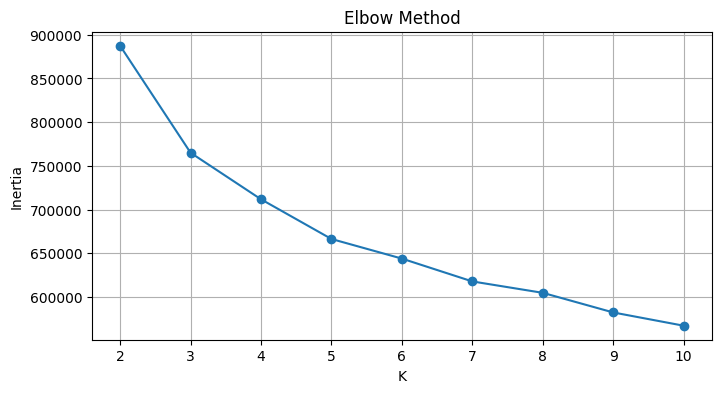

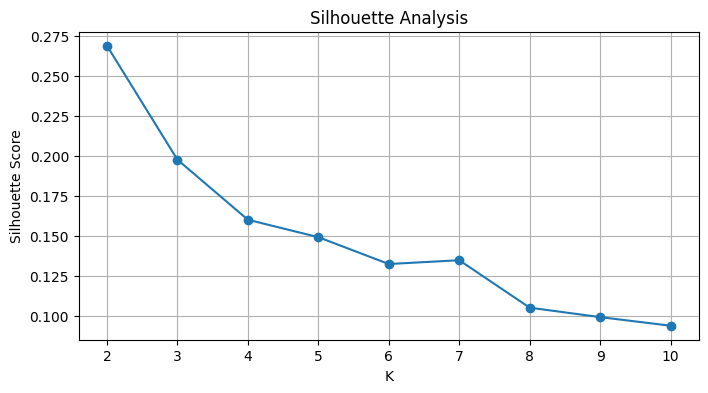

Best K: 2


,K,inertia,silhouette
0,2,887473.2812,0.2690
1,3,764997.1809,0.1977
2,4,711703.6748,0.1601
3,5,666244.9390,0.1492
4,6,643797.6739,0.1324
5,7,617659.1639,0.1348
6,8,604608.3034,0.1051
7,9,582149.5027,0.0992
8,10,566968.0092,0.0938


In [6]:

k_range = range(2, 11)

labels_array, summary_df = cluster_pipeline(
    X_scaled, k_range
)

display(summary_df.round(4))


,Algorithm,Time_sec,Inertia,Silhouette_sample
0,KMeans,0.888,764997.181,0.1977
1,MiniBatchKMeans,0.163,765781.326,0.2009


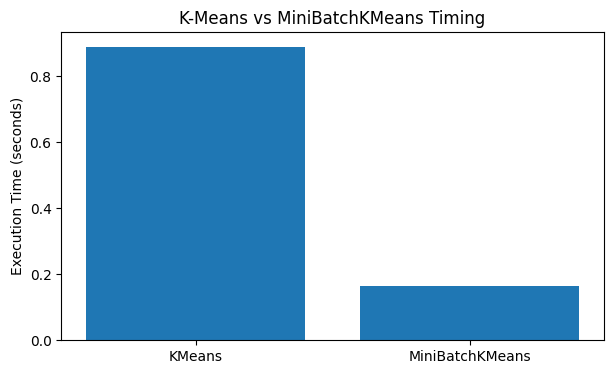

In [8]:

from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import silhouette_score
import time
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

timing_results = []

for name, model in [
    ("KMeans", KMeans(
        n_clusters=3, random_state=42, n_init=3, max_iter=100
    )),
    ("MiniBatchKMeans", MiniBatchKMeans(
        n_clusters=3, random_state=42,
        n_init=3, max_iter=100, batch_size=256
    ))
]:
    start = time.time()
    labels = model.fit_predict(X_scaled)
    elapsed = time.time() - start

    sample_idx = np.random.default_rng(42).choice(
        len(X_scaled),
        size=min(1000, len(X_scaled)),
        replace=False
    )

    score = silhouette_score(
        X_scaled[sample_idx], labels[sample_idx]
    )

    timing_results.append({
        "Algorithm": name,
        "Time_sec": round(elapsed, 3),
        "Inertia": round(model.inertia_, 3),
        "Silhouette_sample": round(score, 4)
    })

timing_df = pd.DataFrame(timing_results)
display(timing_df)

plt.figure(figsize=(7, 4))
plt.bar(timing_df["Algorithm"], timing_df["Time_sec"])
plt.ylabel("Execution Time (seconds)")
plt.title("K-Means vs MiniBatchKMeans Timing")
plt.show()


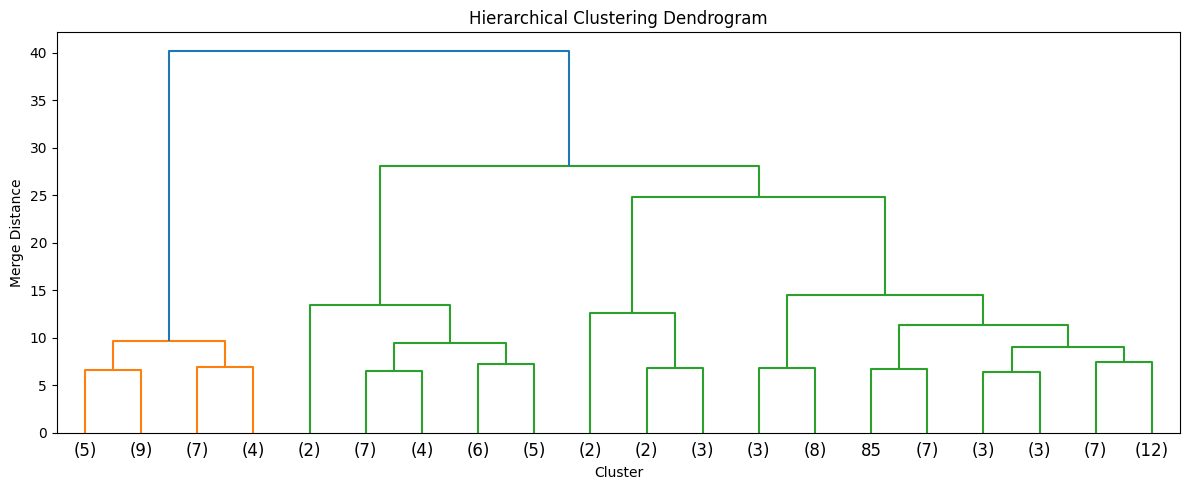

In [9]:

from scipy.cluster.hierarchy import dendrogram, linkage

rng = np.random.default_rng(42)
sample_size = min(100, len(X_scaled))
sample_idx = rng.choice(len(X_scaled), sample_size, replace=False)

X_sample = X_scaled[sample_idx]

linkage_matrix = linkage(X_sample, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(linkage_matrix, truncate_mode="lastp", p=20)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster")
plt.ylabel("Merge Distance")
plt.tight_layout()
plt.show()


In [10]:

from sklearn.cluster import DBSCAN

rng = np.random.default_rng(42)
sample_size = min(1000, len(X_scaled))
sample_idx = rng.choice(len(X_scaled), sample_size, replace=False)
X_db = X_scaled[sample_idx]

dbscan_results = []

for eps in [0.5, 1.0, 1.5]:
    for min_samples in [3, 5, 10]:
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(X_db)

        n_clusters = len(set(labels) - {-1})
        noise = int(np.sum(labels == -1))

        valid = labels != -1
        valid_labels = labels[valid]
        n_valid_clusters = len(set(valid_labels))

        if n_valid_clusters >= 2 and n_valid_clusters < len(valid_labels):
            score = silhouette_score(X_db[valid], valid_labels)
        else:
            score = np.nan

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": n_clusters,
            "noise_points": noise,
            "silhouette": score
        })

dbscan_df = pd.DataFrame(dbscan_results)
display(dbscan_df.round(4))


,eps,min_samples,clusters,noise_points,silhouette
0,0.5,3,0,1000,NaN
1,0.5,5,0,1000,NaN
2,0.5,10,0,1000,NaN
3,1.0,3,0,1000,NaN
4,1.0,5,0,1000,NaN
5,1.0,10,0,1000,NaN
6,1.5,3,0,1000,NaN
7,1.5,5,0,1000,NaN
8,1.5,10,0,1000,NaN


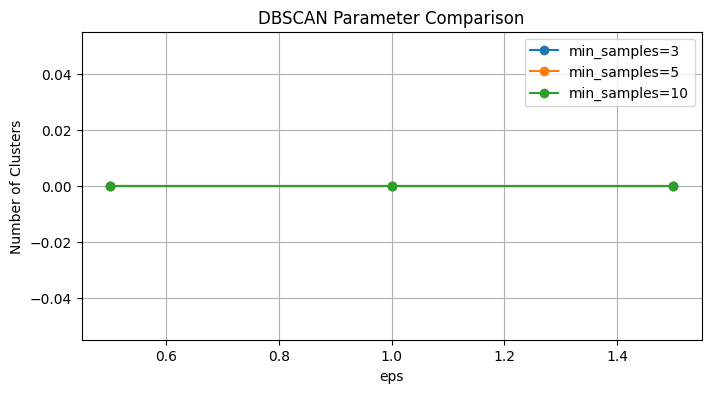

No valid silhouette score for the tested DBSCAN settings.


In [11]:

plt.figure(figsize=(8, 4))

for min_samples in sorted(dbscan_df["min_samples"].unique()):
    subset = dbscan_df[
        dbscan_df["min_samples"] == min_samples
    ]
    plt.plot(
        subset["eps"],
        subset["clusters"],
        marker="o",
        label=f"min_samples={min_samples}"
    )

plt.xlabel("eps")
plt.ylabel("Number of Clusters")
plt.title("DBSCAN Parameter Comparison")
plt.legend()
plt.grid(True)
plt.show()

valid_dbscan = dbscan_df.dropna(subset=["silhouette"])

if not valid_dbscan.empty:
    print("Best DBSCAN setting by silhouette:")
    display(
        valid_dbscan.loc[
            [valid_dbscan["silhouette"].idxmax()]
        ]
    )
else:
    print("No valid silhouette score for the tested DBSCAN settings.")


In [12]:

profile_data = X.select_dtypes(include=np.number).copy()
profile_data["Cluster"] = labels_array

print("Cluster sizes:")
display(
    pd.Series(labels_array, name="Cluster")
    .value_counts()
    .sort_index()
    .rename("Number_of_Samples")
    .to_frame()
)

print("Cluster profile:")
display(profile_data.groupby("Cluster").mean().round(3))


Cluster sizes:


,Number_of_Samples
Cluster,
0,24462
1,25538


Cluster profile:


,StudentID,SGPA_Sem1,SGPA_Sem2,SGPA_Sem3,SGPA_Sem4,SGPA_Sem5,SGPA_Sem6,SGPA_Sem7,SGPA_Sem8,CGPA,...,Workshops,Certifications,Publications,AptitudeTestScore,SoftSkillsRating,CodingTestScore,MockInterviewScore,ExtraCurricular,IsAnomaly,Salary Package
Cluster,,,,,,,,,,,,,,,,,,,,,
0,25004.545,8.390,8.420,8.455,8.489,8.52,8.555,8.584,8.617,8.501,...,2.449,2.678,1.137,77.918,3.753,71.067,67.491,0.661,0.036,16.817
1,24996.625,6.081,6.075,6.067,6.058,6.05,6.048,6.036,6.026,6.044,...,1.188,1.216,0.351,60.151,2.580,44.390,43.795,0.411,0.034,2.562


In [13]:

print("K-Means Summary")
display(summary_df.round(4))

print("Algorithm Timing")
display(timing_df)

print("DBSCAN Results")
display(dbscan_df.round(4))

print("Clustering practical completed successfully!")


K-Means Summary


,K,inertia,silhouette
0,2,887473.2812,0.2690
1,3,764997.1809,0.1977
2,4,711703.6748,0.1601
3,5,666244.9390,0.1492
4,6,643797.6739,0.1324
5,7,617659.1639,0.1348
6,8,604608.3034,0.1051
7,9,582149.5027,0.0992
8,10,566968.0092,0.0938


Algorithm Timing


,Algorithm,Time_sec,Inertia,Silhouette_sample
0,KMeans,0.888,764997.181,0.1977
1,MiniBatchKMeans,0.163,765781.326,0.2009


DBSCAN Results


,eps,min_samples,clusters,noise_points,silhouette
0,0.5,3,0,1000,NaN
1,0.5,5,0,1000,NaN
2,0.5,10,0,1000,NaN
3,1.0,3,0,1000,NaN
4,1.0,5,0,1000,NaN
5,1.0,10,0,1000,NaN
6,1.5,3,0,1000,NaN
7,1.5,5,0,1000,NaN
8,1.5,10,0,1000,NaN


Clustering practical completed successfully!
